# 03. 모델 정의 및 학습

**목표**
- CNN 아키텍처 직접 구현
- 학습 루프 구성 및 실행
- 최적 모델 저장

## 1. 환경 설정

In [1]:
import os, random
from pathlib import Path
from collections import defaultdict

import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 재현성
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ── 데이터 경로 및 상수 ──
RAW_DIR = Path('/data_local') / 'raw'
CLASS_MAP  = {'고추': 'pepper', '배추': 'cabbage', '오이': 'cucumber'}
SPLITS     = ['Training', 'Validation']
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

# ── 이미지 경로 수집 ──
def get_image_paths(raw_dir, splits, class_map):
    data = defaultdict(list)
    for split in splits:
        split_dir = raw_dir / split
        for folder in split_dir.iterdir():
            if not folder.is_dir() or '[원천]' not in folder.name:
                continue
            for kr_name, en_name in class_map.items():
                if kr_name in folder.name:
                    for f in folder.iterdir():
                        if f.suffix.lower() in IMAGE_EXTS:
                            data[en_name].append(f)
    return data

image_paths = get_image_paths(RAW_DIR, SPLITS, CLASS_MAP)

# ── 언더샘플링 ──
MAX_PER_CLASS = 2000
sampled_paths = {cls: random.sample(paths, MAX_PER_CLASS)
                 for cls, paths in image_paths.items()}

# ── train / val / test 분할 ──
CLASS_NAMES  = list(sampled_paths.keys())
CLASS_TO_IDX = {cls: idx for idx, cls in enumerate(CLASS_NAMES)}
all_samples, all_labels = [], []
for cls, paths in sampled_paths.items():
    label = CLASS_TO_IDX[cls]
    for p in paths:
        all_samples.append((p, label))
        all_labels.append(label)

train_data, temp_data, _, temp_labels = train_test_split(
    all_samples, all_labels, test_size=0.2, stratify=all_labels, random_state=SEED)
val_data, test_data = train_test_split(
    temp_data, test_size=0.5, stratify=temp_labels, random_state=SEED)

# ── 정규화 통계 (1,500장 샘플) ──
SAMPLE_N     = 500
sample_paths = random.sample([p for p, _ in train_data],
                             min(SAMPLE_N * len(CLASS_NAMES), len(train_data)))
mean = np.zeros(3)
std  = np.zeros(3)
for path in sample_paths:
    img  = np.array(Image.open(path).convert('RGB').resize((224, 224))) / 255.0
    mean += img.mean(axis=(0, 1))
    std  += img.std(axis=(0, 1))
mean /= len(sample_paths)
std  /= len(sample_paths)
MEAN = mean.tolist()
STD  = std.tolist()

# ── Dataset ──
class CropDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples   = samples
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label

# ── DataLoader ──
IMG_SIZE   = 224
BATCH_SIZE = 32
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
train_loader = DataLoader(CropDataset(train_data, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(CropDataset(val_data,   val_test_transform),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(CropDataset(test_data,  val_test_transform),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# ── 디바이스 ──
DEVICE   = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SAVE_DIR = Path('..') / 'models'
SAVE_DIR.mkdir(exist_ok=True)
SAVE_PATH = SAVE_DIR / 'best_model.pth'

print(f'Device : {DEVICE}')
print(f'MEAN   : {[round(v, 4) for v in MEAN]}')
print(f'STD    : {[round(v, 4) for v in STD]}')
print(f'train {len(train_data)}장 / val {len(val_data)}장 / test {len(test_data)}장')

Device : cuda
MEAN   : [0.4445, 0.5323, 0.327]
STD    : [0.2066, 0.1866, 0.212]
train 4800장 / val 600장 / test 600장


## 2. CNN 아키텍처

- 입력: (N, 3, 224, 224)
- **Conv 블록** (×4): Conv2d(3×3, padding=1) → BatchNorm2d → ReLU → MaxPool2d(2×2)
  - `BatchNorm2d`: 레이어별 출력 분포 정규화 → 학습 안정성
  - `MaxPool2d(2×2)`: 공간 해상도 절반 축소, 위치 불변성 부여
- **채널 수** 32 → 64 → 128 → 256: 공간 해상도 축소에 비례한 채널 증가 → 특징 표현력 유지
- `AdaptiveAvgPool2d(1, 1)`: 공간 차원 집약, FC 입력 크기 고정
- `Dropout(0.5)`: FC 레이어 과적합 방지
- 출력: (N, num_classes)

In [2]:
class CropCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: (N, 3, 224, 224) -> (N, 32, 112, 112)
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            # Block 2: -> (N, 64, 56, 56)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            # Block 3: -> (N, 128, 28, 28)
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            # Block 4: -> (N, 256, 14, 14)
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),  # -> (N, 256, 1, 1)
            nn.Flatten(),                  # -> (N, 256)
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

print('CropCNN 정의 완료')

CropCNN 정의 완료


In [3]:
model = CropCNN(num_classes=len(CLASS_TO_IDX)).to(DEVICE)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'전체 파라미터    : {total_params:,}')
print(f'학습 가능 파라미터: {trainable_params:,}')

전체 파라미터    : 422,659
학습 가능 파라미터: 422,659


In [4]:
from torchinfo import summary as tinfo_summary

print(tinfo_summary(
    CropCNN(),
    input_size=(1, 3, 224, 224),
    device='cuda',
    col_names=['input_size', 'output_size', 'num_params'],
    col_width=22,
    row_settings=['var_names'],
    verbose=1,
))

Layer (type (var_name))                  Input Shape            Output Shape           Param #
CropCNN (CropCNN)                        [1, 3, 224, 224]       [1, 3]                 --
├─Sequential (features)                  [1, 3, 224, 224]       [1, 256, 14, 14]       --
│    └─Conv2d (0)                        [1, 3, 224, 224]       [1, 32, 224, 224]      896
│    └─BatchNorm2d (1)                   [1, 32, 224, 224]      [1, 32, 224, 224]      64
│    └─ReLU (2)                          [1, 32, 224, 224]      [1, 32, 224, 224]      --
│    └─MaxPool2d (3)                     [1, 32, 224, 224]      [1, 32, 112, 112]      --
│    └─Conv2d (4)                        [1, 32, 112, 112]      [1, 64, 112, 112]      18,496
│    └─BatchNorm2d (5)                   [1, 64, 112, 112]      [1, 64, 112, 112]      128
│    └─ReLU (6)                          [1, 64, 112, 112]      [1, 64, 112, 112]      --
│    └─MaxPool2d (7)                     [1, 64, 112, 112]      [1, 64, 56, 56]        --

## 4. 학습 설정

- **Loss**: `CrossEntropyLoss` — 다중 클래스 분류 표준 손실함수 (LogSoftmax + NLLLoss 통합)
- **Optimizer**: `Adam(lr=1e-3)` — 적응적 학습률, 경사 희소성 처리
- **EPOCHS**: 최대 50 — Early Stopping으로 실제 중단 시점 결정
- **Early Stopping**: `patience=5` (val_loss 기준) — 학습 후 val_loss 추이 확인, 결론 테이블에 근거 반영 예정

In [5]:
EPOCHS  = 50
LR      = 1e-3
PATIENCE = 5

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

print(f'EPOCHS    : {EPOCHS}')
print(f'LR        : {LR}')
print(f'PATIENCE  : {PATIENCE}')
print(f'Loss      : {criterion.__class__.__name__}')
print(f'Optimizer : {optimizer.__class__.__name__}')

EPOCHS    : 50
LR        : 0.001
PATIENCE  : 5
Loss      : CrossEntropyLoss
Optimizer : Adam


## 5. 학습 루프

- 매 epoch: train → val 순서로 실행
- `val_acc` 기준 best model 저장 (`best_model.pth`)
- `val_loss` 기준 Early Stopping (`patience=5`)
- `history` dict에 epoch별 loss / accuracy 기록

In [6]:
from tqdm import tqdm

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc  = 0.0
best_val_loss = float('inf')
patience_cnt  = 0

for epoch in range(1, EPOCHS + 1):
    # Train
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(train_loader, desc=f'Epoch {epoch:02d}/{EPOCHS} train', leave=False):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct  += preds.eq(labels).sum().item()
        total    += labels.size(0)

    train_loss = running_loss / total
    train_acc  = correct / total

    # Val
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f'Epoch {epoch:02d}/{EPOCHS} val  ', leave=False):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss    = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            correct  += preds.eq(labels).sum().item()
            total    += labels.size(0)

    val_loss = running_loss / total
    val_acc  = correct / total

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    saved = ''
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), SAVE_PATH)
        saved = ' <- saved'

    print(f'Epoch {epoch:02d}/{EPOCHS}  '
          f'train loss {train_loss:.4f} acc {train_acc:.4f}  '
          f'val loss {val_loss:.4f} acc {val_acc:.4f}{saved}')

    # Early Stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_cnt  = 0
    else:
        patience_cnt += 1
        if patience_cnt >= PATIENCE:
            print(f'\nEarly Stopping at epoch {epoch} (patience={PATIENCE})')
            break

print(f'\nBest val accuracy : {best_val_acc:.4f}')
print(f'모델 저장 경로    : {SAVE_PATH}')

Epoch 01/50  train loss 0.4791 acc 0.8031  val loss 0.4353 acc 0.8417 <- saved


Epoch 02/50  train loss 0.3378 acc 0.8646  val loss 0.2817 acc 0.8933 <- saved


Epoch 03/50  train loss 0.3019 acc 0.8823  val loss 0.2890 acc 0.8950 <- saved


Epoch 04/50  train loss 0.2815 acc 0.8938  val loss 0.2586 acc 0.9133 <- saved


Epoch 05/50  train loss 0.2240 acc 0.9158  val loss 1.0417 acc 0.6450


Epoch 06/50  train loss 0.2142 acc 0.9227  val loss 0.4295 acc 0.8700


... (18 outputs left out)

Epoch 25/50  train loss 0.0844 acc 0.9667  val loss 0.1499 acc 0.9583


Epoch 26/50  train loss 0.0816 acc 0.9700  val loss 0.3514 acc 0.9267


Epoch 27/50  train loss 0.0707 acc 0.9754  val loss 0.1588 acc 0.9633


Epoch 28/50  train loss 0.0869 acc 0.9708  val loss 0.1405 acc 0.9633

Early Stopping at epoch 28 (patience=5)

Best val accuracy : 0.9733
모델 저장 경로    : ../models/best_model.pth


In [7]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
NVIDIA GeForce RTX 3080


## 6. 학습 결과

epoch별 loss / accuracy 곡선 — 수렴 여부 및 과적합 확인

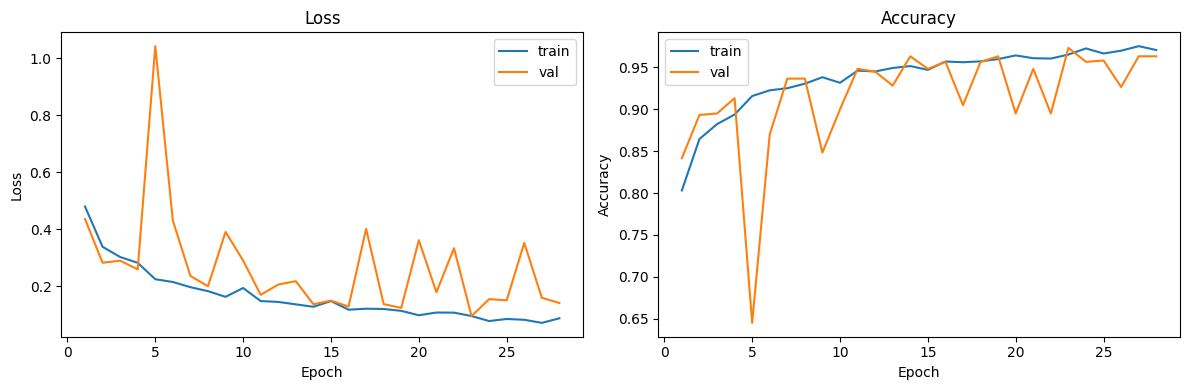

저장: ../results/figures/05_training_curves.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs_range = range(1, len(history['train_loss']) + 1)

axes[0].plot(epochs_range, history['train_loss'], label='train')
axes[0].plot(epochs_range, history['val_loss'],   label='val')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epochs_range, history['train_acc'], label='train')
axes[1].plot(epochs_range, history['val_acc'],   label='val')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
fig_path = Path('..') / 'results' / 'figures' / '05_training_curves.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'저장: {fig_path}')

## 7. 모델 및 학습 결론

| 항목 | 결정 | 근거 |
|---|---|---|
| Conv 블록 수 | 4 | 224×224 입력 → 4회 MaxPool → 14×14 특징 맵; 공간 정보 단계적 추상화 |
| 채널 수 | 32 → 64 → 128 → 256 | 공간 해상도 2배 축소 시 채널 수 2배 증가 — CNN 관행적 패턴 |
| BatchNorm | 각 Conv 블록 적용 | 레이어별 출력 분포 정규화 → 학습 안정성 |
| AdaptiveAvgPool | (1, 1) | 공간 차원 집약, FC 입력 크기 고정; Flatten 후 256차원으로 파라미터 절감 |
| Dropout | 0.5 | FC 레이어 과적합 방지; 비율은 04_experiments에서 조정 |
| Loss | CrossEntropyLoss | 다중 클래스 분류 표준 (LogSoftmax + NLLLoss 통합) |
| Optimizer | Adam(lr=1e-3) | 적응적 학습률, 경사 희소성 처리 |
| Early Stopping | patience=5 (val_loss 기준) | 에폭 수 사전 고정 불필요, 과적합 시점 자동 감지 |
| 모델 저장 | val_acc 기준 best model | 과적합 이전 최적 상태 보존 |

## 8. 테스트 셋 평가 — Confusion Matrix & 클래스별 정확도

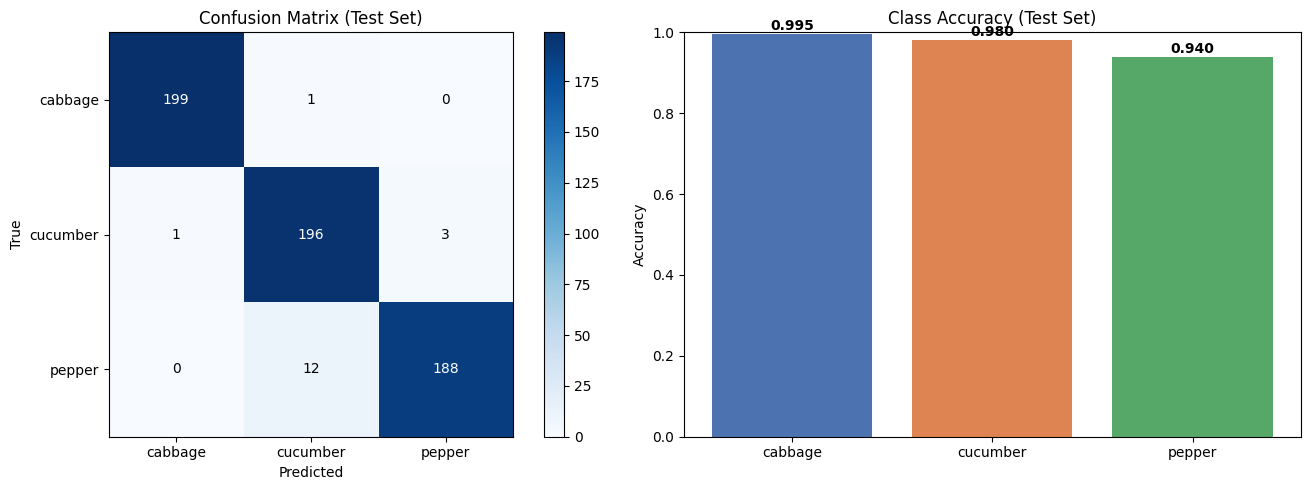


Test Accuracy : 0.9717
  cabbage   : 0.9950
  cucumber  : 0.9800
  pepper    : 0.9400

저장: ../results/figures/06_confusion_matrix.png


In [9]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# best model 로드
model.load_state_dict(torch.load(SAVE_PATH, map_location=DEVICE))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

# ── Confusion Matrix ──
cm = confusion_matrix(all_labels, all_preds)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im = axes[0].imshow(cm, interpolation='nearest', cmap='Blues')
axes[0].set_title('Confusion Matrix (Test Set)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')
axes[0].set_xticks(range(len(CLASS_NAMES)))
axes[0].set_yticks(range(len(CLASS_NAMES)))
axes[0].set_xticklabels(CLASS_NAMES)
axes[0].set_yticklabels(CLASS_NAMES)
plt.colorbar(im, ax=axes[0])
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        axes[0].text(j, i, str(cm[i, j]),
                     ha='center', va='center',
                     color='white' if cm[i, j] > cm.max() / 2 else 'black')

# ── 클래스별 정확도 ──
class_acc = cm.diagonal() / cm.sum(axis=1)
axes[1].bar(CLASS_NAMES, class_acc, color=['#4C72B0', '#DD8452', '#55A868'])
axes[1].set_title('Class Accuracy (Test Set)')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1.0)
for i, v in enumerate(class_acc):
    axes[1].text(i, v + 0.01, f'{v:.3f}', ha='center', fontweight='bold')

plt.tight_layout()
fig_path = Path('..') / 'results' / 'figures' / '06_confusion_matrix.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()

test_acc = (all_preds == all_labels).mean()
print(f'\nTest Accuracy : {test_acc:.4f}')
for cls, acc in zip(CLASS_NAMES, class_acc):
    print(f'  {cls:<10}: {acc:.4f}')
print(f'\n저장: {fig_path}')